In [2]:
# STEP 1: Import Required Libraries

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# STEP 2: Create Customer Dataset

np.random.seed(42)
tf.random.set_seed(42)

# Generate 1000 customer records
number_of_customers = 1000

tenure = np.random.randint(1, 60, number_of_customers)

monthly_charges = np.random.uniform(20, 120, number_of_customers)

data_usage = np.random.randint(1, 50, number_of_customers)

support_tickets = np.random.randint(0, 10, number_of_customers)

# Create Churn column
churn = (((tenure < 12) & (support_tickets > 3)) |
         (monthly_charges > 100)).astype(int)

# Create DataFrame
df = pd.DataFrame({
    'Tenure': tenure,
    'MonthlyCharges': monthly_charges,
    'DataUsage': data_usage,
    'SupportTickets': support_tickets,
    'Churn': churn
})

# Display dataset
print("Customer Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

Customer Dataset:
   Tenure  MonthlyCharges  DataUsage  SupportTickets  Churn
0      39       62.053578         42               2      0
1      52       98.466826          8               8      0
2      29       83.936136         24               3      0
3      15      100.504467         16               6      1
4      43      110.315106         49               8      1

Dataset Shape: (1000, 5)


In [4]:
# STEP 3: Separate Input Features and Target

X = df[['Tenure', 'MonthlyCharges', 'DataUsage', 'SupportTickets']]
y = df['Churn']

print("Input Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Input Features (X):
   Tenure  MonthlyCharges  DataUsage  SupportTickets
0      39       62.053578         42               2
1      52       98.466826          8               8
2      29       83.936136         24               3
3      15      100.504467         16               6
4      43      110.315106         49               8

Target (y):
0    0
1    0
2    0
3    1
4    1
Name: Churn, dtype: int64

X Shape: (1000, 4)
y Shape: (1000,)


In [5]:
# STEP 4: Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (800, 4)
Testing Features: (200, 4)
Training Target: (800,)
Testing Target: (200,)


In [6]:
# STEP 5: Apply Feature Scaling

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed successfully!")
print("\nScaled Training Data:")
print(X_train[:5])

Feature scaling completed successfully!

Scaled Training Data:
[[-1.09835305  0.0987094  -0.19006432  0.20784429]
 [ 0.5520869   1.13968092 -0.84171341 -0.14294776]
 [-0.74468735  0.31537693 -1.13133523  0.20784429]
 [-1.74674017  1.36775623 -1.05892977  1.26022041]
 [ 0.78786403 -0.21525722 -1.34855159 -1.19532389]]


In [7]:
# STEP 6: Build ANN Model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

model = Sequential([
    Input(shape=(4,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

print("ANN Model Created Successfully!")
model.summary()

ANN Model Created Successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
# STEP 7: Compile ANN Model

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("ANN Model Compiled Successfully!")

ANN Model Compiled Successfully!


In [9]:
# STEP 8: Train ANN Model

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("ANN Model Training Completed!")

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.5828 - loss: 0.6636 - val_accuracy: 0.6375 - val_loss: 0.6264
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6766 - loss: 0.6040 - val_accuracy: 0.7125 - val_loss: 0.5721
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7469 - loss: 0.5587 - val_accuracy: 0.7688 - val_loss: 0.5311
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8047 - loss: 0.5209 - val_accuracy: 0.8062 - val_loss: 0.4962
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8344 - loss: 0.4856 - val_accuracy: 0.8375 - val_loss: 0.4642
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8516 - loss: 0.4526 - val_accuracy: 0.8438 - val_loss: 0.4348
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8687 - loss: 0.4227 - val_accuracy: 0.8375 - val_loss: 0.4081
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8609 - loss: 0.3964 - val_accuracy: 0.8313 - 

In [10]:
# STEP 9: Evaluate ANN Model

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("\nModel Evaluation Results:")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9450 - loss: 0.0955  

Model Evaluation Results:
Test Loss: 0.09552253037691116
Test Accuracy: 94.49999928474426 %


In [11]:
# STEP 10: Display Model Summary

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 677 (2.65 KB)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 452 (1.77 KB)

In [12]:
# STEP 11: Predict New Customer Churn

new_customer = np.array([[10, 110, 20, 5]])

new_customer_scaled = scaler.transform(new_customer)

prediction = model.predict(new_customer_scaled)

print("Churn Probability:", prediction[0][0])

if prediction[0][0] > 0.5:
    print("Predicted Churn: Yes")
else:
    print("Predicted Churn: No")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step
Churn Probability: 0.99927723
Predicted Churn: Yes


In [13]:
# STEP 12: Training and Validation Accuracy

print("Training Accuracy:")
print(history.history['accuracy'][-1])

print("\nValidation Accuracy:")
print(history.history['val_accuracy'][-1])

Training Accuracy:
0.987500011920929

Validation Accuracy:
0.987500011920929


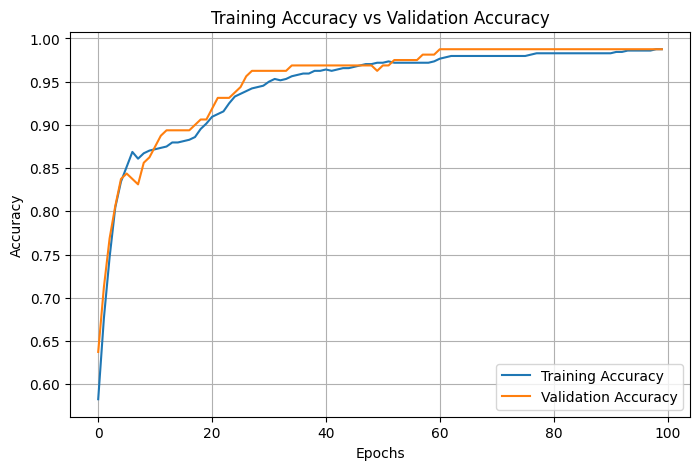

In [14]:
# STEP 13: Plot Training vs Validation Accuracy

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training Accuracy vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

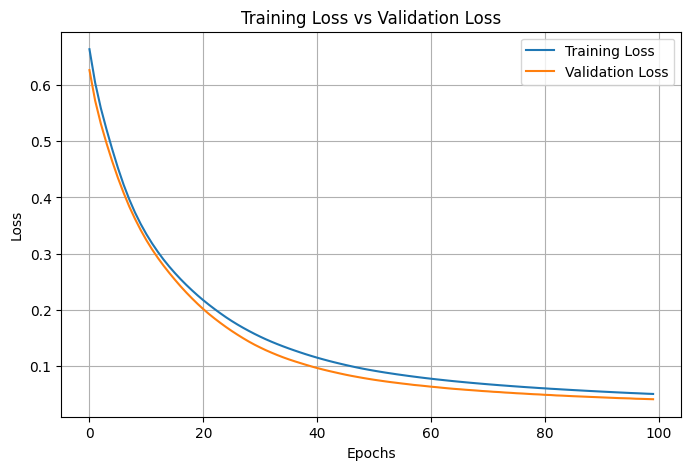

In [15]:
# STEP 14: Training and Validation Loss Graph

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training Loss vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [16]:
# STEP 15: Final Project Results

print("===== CUSTOMER CHURN PREDICTION =====")

print("\nDataset Shape:", df.shape)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTest Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

print("\nModel Architecture:")
model.summary()

print("\nPROJECT COMPLETED SUCCESSFULLY!")

===== CUSTOMER CHURN PREDICTION =====

Dataset Shape: (1000, 5)

Training Samples: 800
Testing Samples: 200

Test Accuracy: 94.5 %
Test Loss: 0.0955

Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 677 (2.65 KB)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 452 (1.77 KB)


PROJECT COMPLETED SUCCESSFULLY!
